In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df = pd.read_excel("AVERAGE_FXRATES_17.xlsx",skiprows=4, header=None)

In [6]:
clean_columns = [
    'Empty_Prefix',
    'Date',
    'Dollar_Buy', 'Dollar_Sale',
    'Pound_Buy', 'Pound_Sale',
    'Euro_Buy', 'Euro_Sale',
    'Rand_Buy', 'Rand_Sale'
]
df.columns = clean_columns
df = df.drop(columns=['Empty_Prefix'])
df = df.dropna(subset=['Date'])
rate_cols = ['Dollar_Buy', 'Dollar_Sale', 'Pound_Buy', 'Pound_Sale', 'Euro_Buy', 'Euro_Sale', 'Rand_Buy', 'Rand_Sale']
for col in rate_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date'])

In [7]:
print(df)

           Date    Dollar_Buy  Dollar_Sale    Pound_Buy   Pound_Sale  \
0    2006-01-03   3467.407407  3528.518519  5984.400000  6090.930000   
1    2006-01-04  43649.000000     0.645833    12.859412     0.057196   
2    2006-01-05  43650.000000     0.395833    12.876471     0.132568   
3    2006-01-06  43650.000000     0.520833    12.851471    -0.194341   
4    2006-01-09  43650.000000     0.645833    12.831471    -0.155745   
...         ...           ...          ...          ...          ...   
5076 2026-06-17     17.767107    17.817107    23.829244    23.910558   
5077 2026-06-18     17.853929    17.903929    23.638601    23.710173   
5078 2026-06-19     17.893571    17.943571    23.662459    23.733962   
5079 2026-06-22     17.806310    17.855833    23.580896    23.651837   
5080 2026-06-23     17.900000    17.950000    23.645900    23.717335   

         Euro_Buy    Euro_Sale    Rand_Buy   Rand_Sale  
0     4116.510000  4190.120000  551.630000  561.080000  
1       12.732881    

In [8]:
x = df.drop(['Pound_Sale'],axis=1)
y = df['Pound_Sale']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
train_data = pd.concat([X_train, y_train], axis=1)
test_data = pd.concat([X_test, y_test], axis=1)

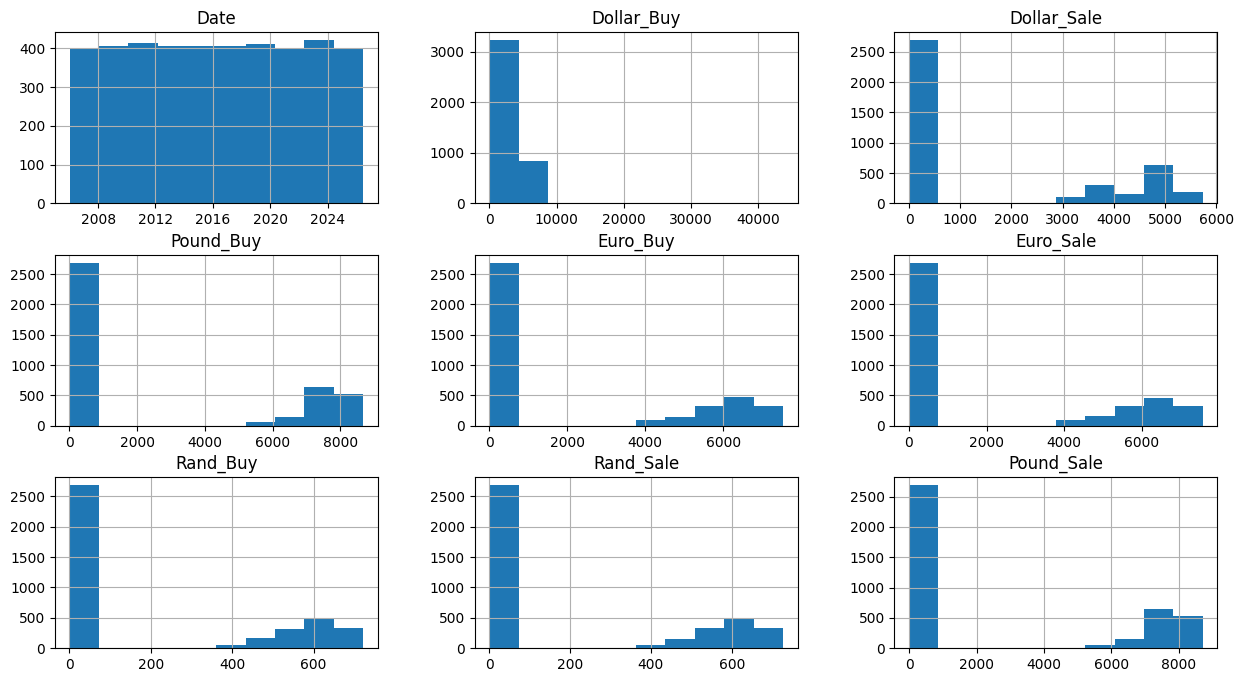

<Axes: >

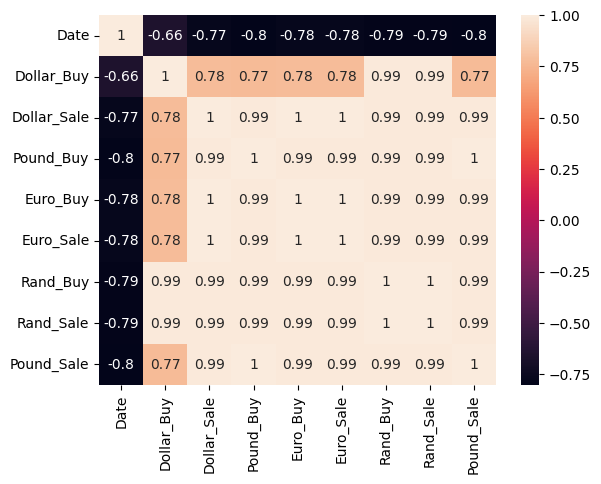

In [9]:
train_data.hist(figsize=(15,8))
plt.show()
sns.heatmap(train_data.corr(), annot=True)

In [10]:
print(train_data.corr())

                 Date  Dollar_Buy  Dollar_Sale  Pound_Buy  Euro_Buy  \
Date         1.000000   -0.659613    -0.774969  -0.800523 -0.776075   
Dollar_Buy  -0.659613    1.000000     0.780870   0.774175  0.778686   
Dollar_Sale -0.774969    0.780870     1.000000   0.991807  0.997050   
Pound_Buy   -0.800523    0.774175     0.991807   1.000000  0.992311   
Euro_Buy    -0.776075    0.778686     0.997050   0.992311  1.000000   
Euro_Sale   -0.776813    0.778713     0.997102   0.992489  0.999994   
Rand_Buy    -0.789240    0.991265     0.991453   0.991168  0.990726   
Rand_Sale   -0.789641    0.991109     0.991304   0.991084  0.990565   
Pound_Sale  -0.801186    0.773964     0.991669   0.999992  0.992105   

             Euro_Sale  Rand_Buy  Rand_Sale  Pound_Sale  
Date         -0.776813 -0.789240  -0.789641   -0.801186  
Dollar_Buy    0.778713  0.991265   0.991109    0.773964  
Dollar_Sale   0.997102  0.991453   0.991304    0.991669  
Pound_Buy     0.992489  0.991168   0.991084    0.999992  

In [11]:
train_data['Dollar_Sale'] = np.log(train_data['Dollar_Sale'] + 1)
train_data['Pound_Sale'] = np.log(train_data['Pound_Sale'] + 1)
train_data['Euro_Sale'] = np.log(train_data['Euro_Sale'] + 1)
train_data['Rand_Sale'] = np.log(train_data['Rand_Sale'] + 1)

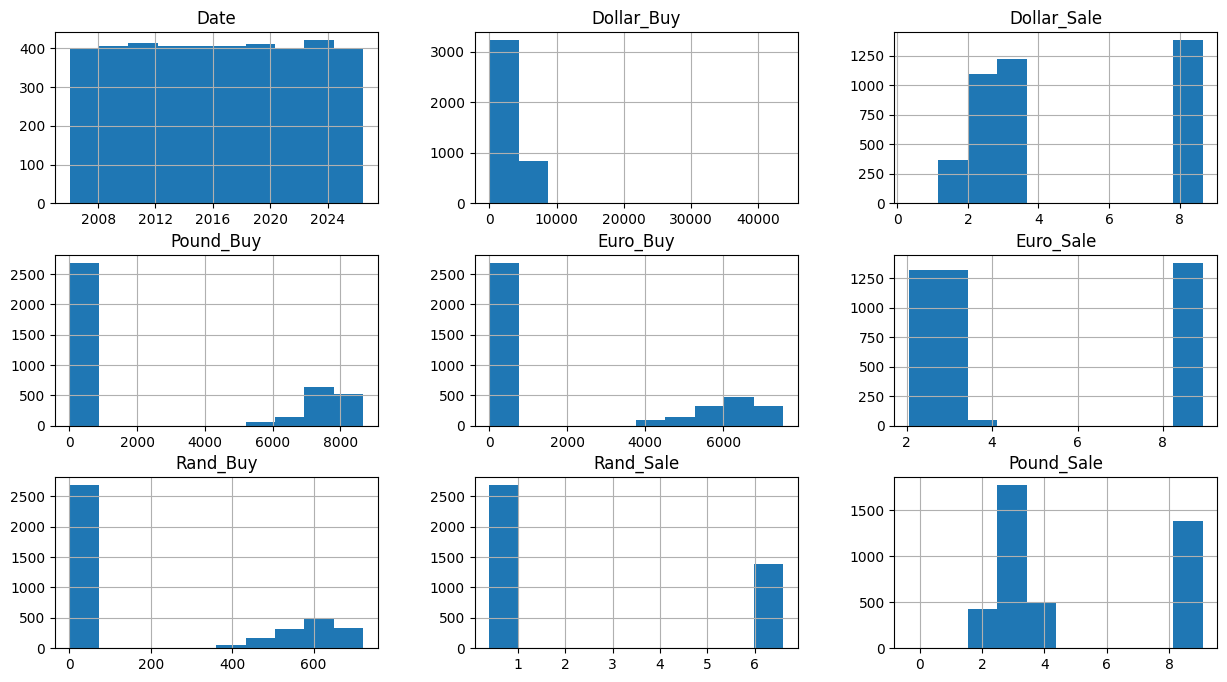

In [12]:
train_data.hist(figsize=(15,8))
plt.show()

In [18]:
target_colums = ['Dollar_Buy', 'Dollar_Sale',
    'Pound_Buy', 'Pound_Sale',
    'Euro_Buy', 'Euro_Sale',
    'Rand_Buy', 'Rand_Sale']
for target_col in target_colums:
  df['day1'] = df[target_col].shift(1)
  df['day2'] = df[target_col].shift(2)
  df['day3'] = df[target_col].shift(3)

  day_model = df.dropna(subset=['day1', 'day2', 'day3', target_col])

  x = day_model[['day1', 'day2', 'day3']]
  y = day_model[target_col]

  train_size = int(len(x) * 0.8)
  X_train, X_test = x.iloc[:train_size], x.iloc[train_size:]
  y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

  model = LinearRegression()
  model.fit(X_train, y_train)

  prediction = model.predict(X_test)
  mae = mean_absolute_error(y_test, prediction)
  print(f"The Mean Absolute Error is {mae:.2f}")

  curr_data = df[target_col].iloc[-3:].values
  tmr_rate = model.predict([[curr_data[2], curr_data[1], curr_data[0]]])
  print(f"Predicted {target_col} for tomorrow: {tmr_rate[0]:.2f}")

The Mean Absolute Error is 106.19
Predicted Dollar_Buy for tomorrow: 124.34
The Mean Absolute Error is 1.87
Predicted Dollar_Sale for tomorrow: 19.82
The Mean Absolute Error is 3.13
Predicted Pound_Buy for tomorrow: 26.78
The Mean Absolute Error is 3.17
Predicted Pound_Sale for tomorrow: 26.90
The Mean Absolute Error is 2.34
Predicted Euro_Buy for tomorrow: 22.73
The Mean Absolute Error is 2.36
Predicted Euro_Sale for tomorrow: 22.82
The Mean Absolute Error is 0.03
Predicted Rand_Buy for tomorrow: 1.12
The Mean Absolute Error is 0.03
Predicted Rand_Sale for tomorrow: 1.12


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/